# Simulasi Problem 1 – Dudukan Mesin Retak

Pada Problem 1, ditemukan retak di sekitar lubang baut dudukan mesin. Waktu sebelum endurance terbatas, sehingga tim perlu membandingkan **penguatan dudukan yang ada** dengan **pembuatan desain baru yang lebih ringan**.

Simulasi ini membandingkan tiga kondisi:
1. Dudukan yang masih retak (hanya sebagai pembanding, bukan pilihan untuk dipakai).
2. Dudukan yang diperkuat setelah retak ditangani dan diperiksa.
3. Desain baru yang lebih ringan.

Strukturnya mengikuti notebook contoh: penjelasan, parameter, fungsi, menjalankan simulasi, kemudian grafik.


## 1. MODEL SEDERHANA DAN ASUMSI

Agar dapat disimulasikan dengan Python dasar, dudukan dianggap sebagai pelat sederhana yang menerima beban tarik ekuivalen.

Persamaan yang digunakan:

\[
A = w 	imes t
\]
\[
σ_{nom} = rac{F_{jalur}}{A}, \qquad
σ_{lokal} = K_t 	imes σ_{nom}
\]
\[
SF = rac{σ_y}{σ_{lokal}}, \qquad
m = ρ 	imes V
\]

Asumsi simulasi: gaya total desain 3000 N, terbagi ke dua jalur beban; kekuatan luluh material 250 MPa; massa jenis 7850 kg/m³; waktu tersedia 3 hari; dan ruang pemasangan maksimum 110 mm. Semua angka ini **hanya asumsi contoh**, bukan data mobil sebenarnya.

Faktor konsentrasi tegangan \(K_t\) juga diasumsikan untuk membandingkan bentuk dudukan. Model ini hanya screening tegangan statis sederhana. Model ini belum menghitung fatigue, pertumbuhan retak, bending kompleks, beban baut, sambungan las, atau dinamika mesin. Karena itu, nilai SF tidak dapat dipakai sebagai sertifikasi keamanan komponen nyata.


## 2. IMPORT LIBRARY
Library yang digunakan hanya NumPy untuk perhitungan dan Matplotlib untuk grafik.

In [1]:
# ---------------------------------
#           Impor Library
# ---------------------------------
import numpy as np
import matplotlib.pyplot as plt


## 3. PARAMETER SISTEM
Parameter berikut mewakili tiga alternatif. Massa dihitung dari pendekatan bentuk pelat, sedangkan dimensi paket menunjukkan kebutuhan ruang pemasangan.

In [2]:
# ---------------------------------
#       Tentukan Parameter Sistem
# ---------------------------------

# --- Beban dan material (ASUMSI) ---
F_design_total = 3000.0  # Gaya total desain pada kelompok dudukan (N)
n_load_path = 2         # Diasumsikan beban terbagi ke 2 jalur dudukan
strength_yield = 250.0  # Tegangan luluh material asumsi (MPa)
density = 7850.0        # Massa jenis material asumsi (kg/m^3)

# --- Batasan tim ---
deadline_days = 3.0     # Waktu yang tersedia sebelum endurance (hari)
max_package_mm = 110.0  # Ruang maksimum yang tersedia (mm)
SF_min = 2.0            # Target faktor keamanan awal untuk screening

# --- Pilihan kondisi dudukan ---
# Lebar dan tebal dipakai untuk menghitung luas penampang sederhana.
# Panjang dipakai untuk estimasi massa pelat sederhana.
kandidat = {
    "Dudukan retak (acuan)": {
        "width_mm": 40.0,
        "thickness_mm": 3.0,
        "length_mm": 80.0,
        "Kt": 3.0,
        "package_mm": 100.0,
        "work_days": 0.0,
        "crack_present": True,
    },
    "Diperkuat": {
        "width_mm": 40.0,
        "thickness_mm": 5.0,
        "length_mm": 80.0,
        "Kt": 2.0,
        "package_mm": 108.0,
        "work_days": 1.5,
        # Diasumsikan retak sudah ditangani dan diperiksa sebelum penguatan.
        "crack_present": False,
    },
    "Desain baru": {
        "width_mm": 32.0,
        "thickness_mm": 2.8,
        "length_mm": 80.0,
        "Kt": 1.5,
        "package_mm": 92.0,
        "work_days": 4.5,
        "crack_present": False,
    },
}


## 4. FUNGSI YANG DIPERLUKAN
Fungsi pertama menghitung estimasi massa. Fungsi kedua menghitung tegangan lokal di area kritis. Fungsi ketiga memeriksa batas awal faktor keamanan, waktu pengerjaan, dan ruang pemasangan.

In [3]:
# ---------------------------------
#         Fungsi Diperlukan
# ---------------------------------

def hitung_massa(width_mm, thickness_mm, length_mm):
    """Estimasi massa dengan pendekatan bentuk pelat sederhana."""
    volume_m3 = width_mm * thickness_mm * length_mm * 1e-9
    return density * volume_m3


def hitung_stress(F_total, data):
    """Menghitung tegangan lokal sederhana di sekitar area kritis."""
    F_per_path = F_total / n_load_path
    area_mm2 = data["width_mm"] * data["thickness_mm"]

    # N/mm^2 sama dengan MPa
    stress_nominal = F_per_path / area_mm2
    stress_local = data["Kt"] * stress_nominal
    return stress_local


def evaluasi_kandidat(nama, data):
    """Menghitung massa, tegangan, faktor keamanan, dan kelayakan awal."""
    massa = hitung_massa(
        data["width_mm"], data["thickness_mm"], data["length_mm"]
    )
    stress = hitung_stress(F_design_total, data)
    SF = strength_yield / stress

    # Dudukan yang masih memiliki retak tidak boleh dianggap layak dipakai.
    aman_awal = SF >= SF_min and not data["crack_present"]
    cukup_waktu = data["work_days"] <= deadline_days
    cukup_ruang = data["package_mm"] <= max_package_mm
    layak = aman_awal and cukup_waktu and cukup_ruang

    return {
        "name": nama,
        "mass": massa,
        "stress": stress,
        "SF": SF,
        "safe_screening": aman_awal,
        "time_ok": cukup_waktu,
        "space_ok": cukup_ruang,
        "feasible": layak,
    }


## 5. JALANKAN SIMULASI
Hasil tiap alternatif ditampilkan dalam bentuk massa, tegangan, faktor keamanan, waktu, dan kebutuhan ruang.

In [4]:
# ---------------------------------
#        Jalankan Simulasi
# ---------------------------------

print("Menjalankan simulasi Problem 1...\n")

hasil = {}
for nama, data in kandidat.items():
    hasil[nama] = evaluasi_kandidat(nama, data)

print("--- HASIL PERBANDINGAN ---")
for nama, data in kandidat.items():
    h = hasil[nama]
    print(f"\n{nama}")
    print(f"  Massa estimasi       : {h['mass']:.3f} kg")
    print(f"  Tegangan lokal       : {h['stress']:.2f} MPa")
    print(f"  Faktor keamanan      : {h['SF']:.2f}")
    print(f"  Waktu pengerjaan     : {data['work_days']:.1f} hari")
    print(f"  Kebutuhan ruang      : {data['package_mm']:.1f} mm")
    print(f"  Kondisi masih retak  : {data['crack_present']}")
    print(f"  Memenuhi batas waktu : {h['time_ok']}")
    print(f"  Memenuhi ruang       : {h['space_ok']}")
    print(f"  Layak awal           : {h['feasible']}")


Menjalankan simulasi Problem 1...

--- HASIL PERBANDINGAN ---

Dudukan retak (acuan)
  Massa estimasi       : 0.075 kg
  Tegangan lokal       : 37.50 MPa
  Faktor keamanan      : 6.67
  Waktu pengerjaan     : 0.0 hari
  Kebutuhan ruang      : 100.0 mm
  Kondisi masih retak  : True
  Memenuhi batas waktu : True
  Memenuhi ruang       : True
  Layak awal           : False

Diperkuat
  Massa estimasi       : 0.126 kg
  Tegangan lokal       : 15.00 MPa
  Faktor keamanan      : 16.67
  Waktu pengerjaan     : 1.5 hari
  Kebutuhan ruang      : 108.0 mm
  Kondisi masih retak  : False
  Memenuhi batas waktu : True
  Memenuhi ruang       : True
  Layak awal           : True

Desain baru
  Massa estimasi       : 0.056 kg
  Tegangan lokal       : 25.11 MPa
  Faktor keamanan      : 9.96
  Waktu pengerjaan     : 4.5 hari
  Kebutuhan ruang      : 92.0 mm
  Kondisi masih retak  : False
  Memenuhi batas waktu : False
  Memenuhi ruang       : True
  Layak awal           : False


## 6. SIMULASI PERUBAHAN BEBAN
Beban dinaikkan dari 0,5 sampai 2 kali beban asumsi untuk melihat bagaimana tegangan dan faktor keamanan berubah.

In [5]:
# ---------------------------------
#    Simulasi Perubahan Beban
# ---------------------------------

load_multiplier = np.linspace(0.5, 2.0, 60)

stress_history = {}
SF_history = {}

for nama, data in kandidat.items():
    stress_values = []
    SF_values = []

    for multiplier in load_multiplier:
        F_now = F_design_total * multiplier
        stress_now = hitung_stress(F_now, data)
        SF_now = strength_yield / stress_now

        stress_values.append(stress_now)
        SF_values.append(SF_now)

    stress_history[nama] = np.array(stress_values)
    SF_history[nama] = np.array(SF_values)


## 7. PLOT TEGANGAN LOKAL
Grafik ini memperlihatkan respons tegangan saat beban bertambah.

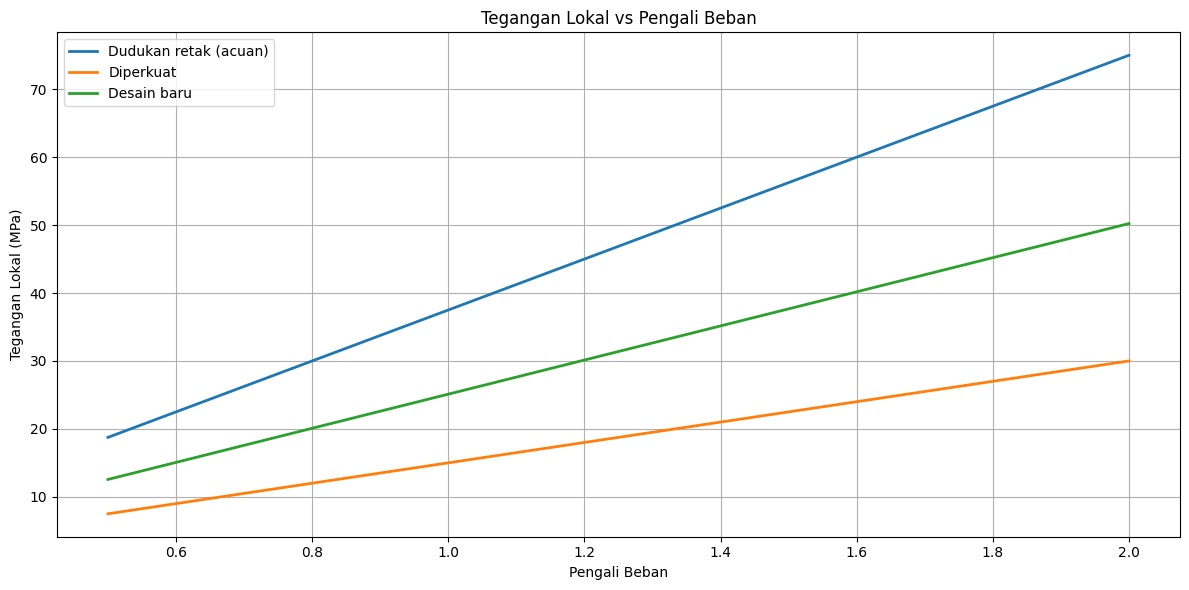

In [6]:
# ---------------------------------
#        Plot Tegangan
# ---------------------------------

plt.figure(figsize=(12, 6))
for nama in kandidat:
    plt.plot(load_multiplier, stress_history[nama], label=nama, linewidth=2)

plt.title("Tegangan Lokal vs Pengali Beban")
plt.xlabel("Pengali Beban")
plt.ylabel("Tegangan Lokal (MPa)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


## 8. PLOT FAKTOR KEAMANAN
Garis putus-putus menunjukkan target screening awal SF = 2. Dudukan yang masih retak tetap tidak dianggap layak, meskipun hasil hitungan statis terlihat memenuhi angka tersebut.

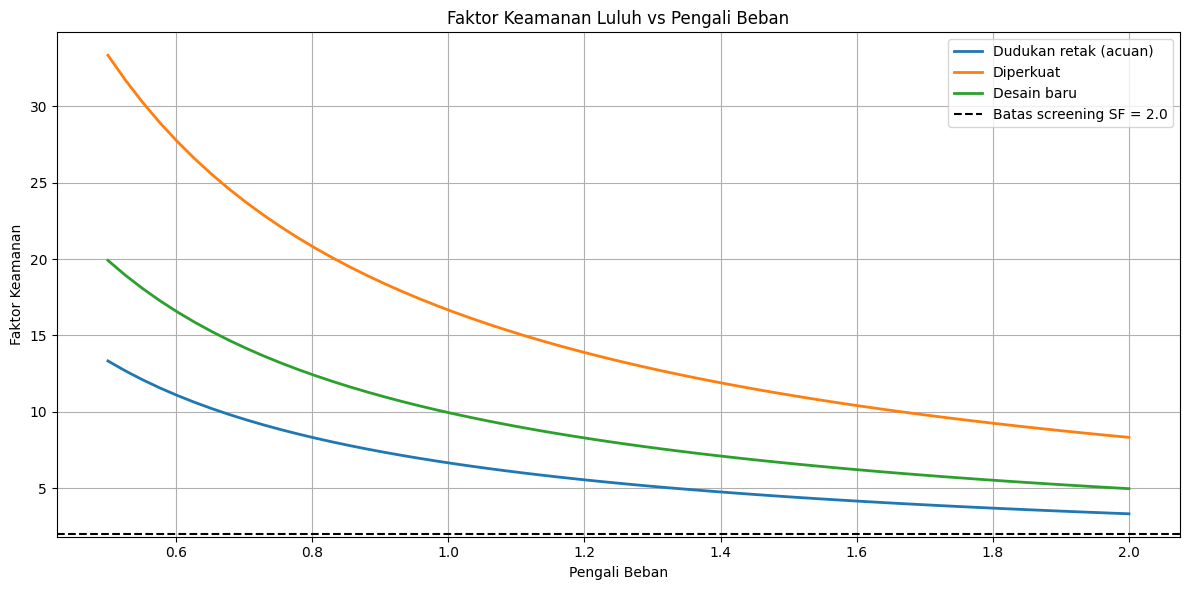

In [7]:
# ---------------------------------
#    Plot Faktor Keamanan
# ---------------------------------

plt.figure(figsize=(12, 6))
for nama in kandidat:
    plt.plot(load_multiplier, SF_history[nama], label=nama, linewidth=2)

plt.axhline(
    y=SF_min,
    color="black",
    linestyle="--",
    label=f"Batas screening SF = {SF_min}",
)
plt.title("Faktor Keamanan Luluh vs Pengali Beban")
plt.xlabel("Pengali Beban")
plt.ylabel("Faktor Keamanan")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


## 9. PERBANDINGAN MASSA
Grafik ini membantu melihat konsekuensi massa dari setiap alternatif.

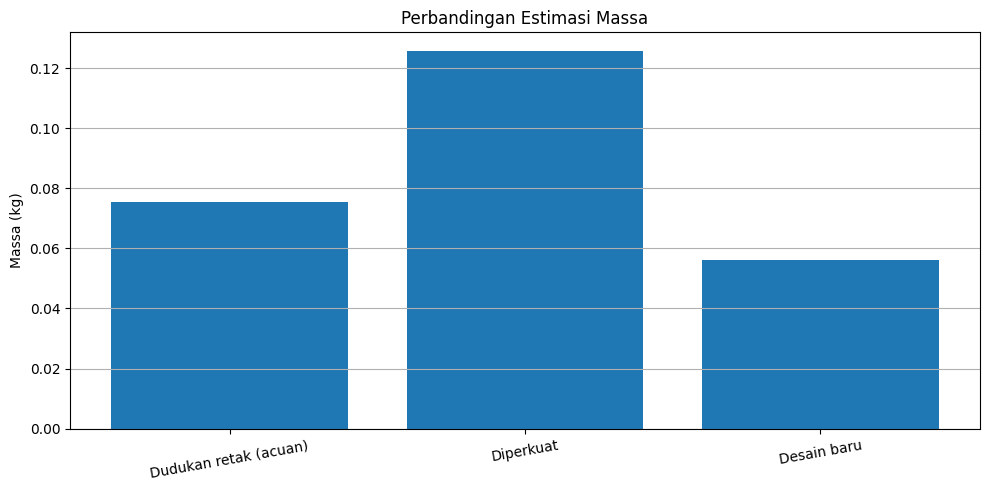

In [8]:
# ---------------------------------
#       Plot Massa Dudukan
# ---------------------------------

nama_kandidat = list(kandidat.keys())
massa = [hasil[nama]["mass"] for nama in nama_kandidat]

plt.figure(figsize=(10, 5))
plt.bar(nama_kandidat, massa)
plt.title("Perbandingan Estimasi Massa")
plt.ylabel("Massa (kg)")
plt.xticks(rotation=10)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


## 10. WAKTU DAN RUANG PEMASANGAN
Dua grafik berikut menunjukkan apakah alternatif bisa selesai sebelum deadline dan muat di ruang yang tersedia.

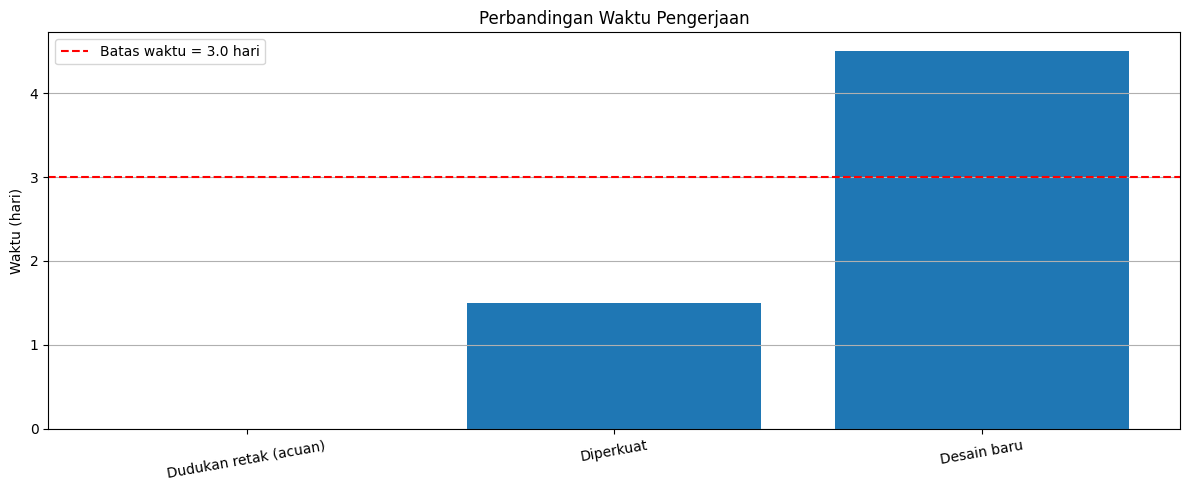

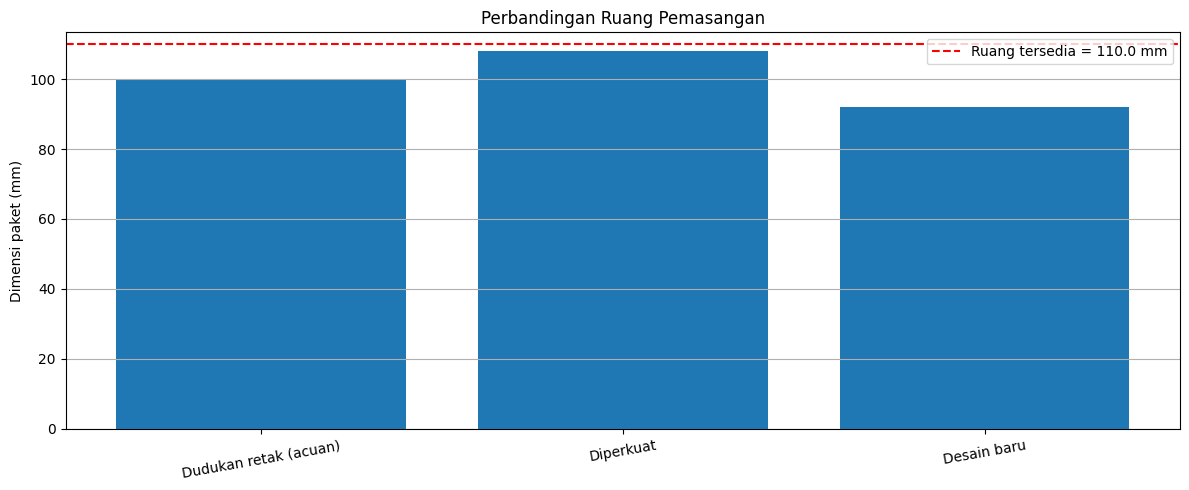

In [9]:
# ---------------------------------
#   Plot Waktu dan Ruang Pemasangan
# ---------------------------------

waktu = [kandidat[nama]["work_days"] for nama in nama_kandidat]
ruang = [kandidat[nama]["package_mm"] for nama in nama_kandidat]

plt.figure(figsize=(12, 5))
plt.bar(nama_kandidat, waktu)
plt.axhline(
    y=deadline_days,
    color="red",
    linestyle="--",
    label=f"Batas waktu = {deadline_days} hari",
)
plt.title("Perbandingan Waktu Pengerjaan")
plt.ylabel("Waktu (hari)")
plt.xticks(rotation=10)
plt.grid(axis="y")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5))
plt.bar(nama_kandidat, ruang)
plt.axhline(
    y=max_package_mm,
    color="red",
    linestyle="--",
    label=f"Ruang tersedia = {max_package_mm} mm",
)
plt.title("Perbandingan Ruang Pemasangan")
plt.ylabel("Dimensi paket (mm)")
plt.xticks(rotation=10)
plt.grid(axis="y")
plt.legend()
plt.tight_layout()
plt.show()


In [10]:
# ---------------------------------
#           Kesimpulan
# ---------------------------------

print("\n--- KESIMPULAN SIMULASI ---")
print(
    "Dengan asumsi yang dipakai, penguatan menjadi pilihan sementara "
    "karena memenuhi batas waktu dan ruang serta memiliki faktor keamanan "
    "screening di atas target."
)
print(
    "Desain baru lebih ringan dan membutuhkan ruang lebih kecil, tetapi "
    "waktu pembuatannya melewati batas waktu yang diasumsikan."
)
print(
    "Dudukan yang masih retak tidak dipilih untuk digunakan kembali, "
    "meskipun hasil hitungan tegangan sederhananya terlihat cukup."
)
print(
    "Hasil ini hanya simulasi awal. Keputusan nyata tetap memerlukan "
    "pemeriksaan retak, data material dan beban aktual, analisis detail, "
    "serta validasi oleh engineer yang bertanggung jawab."
)



--- KESIMPULAN SIMULASI ---
Dengan asumsi yang dipakai, penguatan menjadi pilihan sementara karena memenuhi batas waktu dan ruang serta memiliki faktor keamanan screening di atas target.
Desain baru lebih ringan dan membutuhkan ruang lebih kecil, tetapi waktu pembuatannya melewati batas waktu yang diasumsikan.
Dudukan yang masih retak tidak dipilih untuk digunakan kembali, meskipun hasil hitungan tegangan sederhananya terlihat cukup.
Hasil ini hanya simulasi awal. Keputusan nyata tetap memerlukan pemeriksaan retak, data material dan beban aktual, analisis detail, serta validasi oleh engineer yang bertanggung jawab.


## 11. ANALISIS DAN KESIMPULAN

Berdasarkan angka asumsi, **penguatan menjadi pilihan sementara yang paling masuk akal** karena waktu pengerjaan dan kebutuhan ruang masih berada di dalam batas. Penguatan juga memberi estimasi tegangan lokal yang lebih rendah pada model sederhana ini.

Desain baru memiliki massa dan kebutuhan ruang lebih kecil, tetapi waktu pengerjaannya melewati batas 3 hari. Desain baru dapat dipertimbangkan setelah endurance atau untuk iterasi berikutnya. Dudukan yang masih retak tidak boleh dipakai kembali hanya karena nilai faktor keamanan statis terlihat cukup.

### Pemeriksaan sebelum mobil digunakan kembali

1. Periksa pola dan lokasi awal retak, kondisi lubang baut, permukaan kontak, baut, serta dudukan lain yang menerima beban serupa.
2. Cari penyebab yang mungkin: konsentrasi tegangan di lubang, beban torsi mesin, getaran berulang, ketidaksejajaran pemasangan, baut longgar, atau masalah manufaktur.
3. Cocokkan inspeksi lanjutan/NDT dengan material dan geometri komponen, lalu pastikan retak sudah ditangani dan tidak ada indikasi retak tersisa yang tidak dapat diterima.
4. Gunakan data material dan beban aktual untuk analisis lebih detail. Periksa juga kekuatan baut/sambungan, fatigue, perubahan massa, dan clearance saat mesin bergerak.
5. Lakukan validasi terkontrol dan inspeksi ulang setelah pengujian. Mobil baru boleh digunakan setelah hasilnya ditinjau dan disetujui engineer yang bertanggung jawab.

**Catatan penting:** simulasi ini adalah latihan pemodelan untuk membandingkan trade-off, bukan panduan fabrikasi atau bukti bahwa dudukan tertentu aman. Geometri, material, beban, metode perbaikan, dan hasil inspeksi aktual wajib diverifikasi sebelum komponen dipakai.
